## TUGAS 2 PEMOGRAMAN PARALEL

## NO.1a Tanpa lock

In [13]:
import threading
import time

saldo = 1_000_000

def tarik_setor(jumlah_iterasi):
    global saldo
    for _ in range(jumlah_iterasi):
        # Sengaja dipecah (baca -> jeda -> tulis) agar race condition mudah teramati
        temp = saldo
        time.sleep(0)
        saldo = temp - 1     # tarik 1
        temp = saldo
        time.sleep(0)
        saldo = temp + 1     # setor 1

threads = [threading.Thread(target=tarik_setor, args=(10_000,)) for _ in range(10)]
for t in threads:
    t.start()
for t in threads:
    t.join()

print(f"Saldo seharusnya : {1_000_000:,}")
print(f"Saldo aktual     : {saldo:,}")
print(f"Selisih          : {1_000_000 - saldo:,}")

Saldo seharusnya : 1,000,000
Saldo aktual     : 999,999
Selisih          : 1


saldo -= 1 dan saldo += 1 bukan operasi atomik (terdiri dari baca, hitung, tulis). Jika dua thread membaca nilai yang sama lalu sama-sama menulis, salah satu update hilang (race condition). Hasilnya bisa berbeda tiap kali dijalankan, dan pada Python versi baru saldo akhir kadang kebetulan tetap 1.000.000 karena celahnya sangat sempit.

## NO.1b dengan lock

In [15]:
saldo = 1_000_000
lock = threading.Lock()

def tarik_setor_lock(jumlah_iterasi):
    global saldo
    for _ in range(jumlah_iterasi):
        with lock:
            saldo -= 1   # tarik 1
            saldo += 1   # setor 1

threads = [threading.Thread(target=tarik_setor_lock, args=(10_000,)) for _ in range(10)]
for t in threads:
    t.start()
for t in threads:
    t.join()

print(f"Saldo seharusnya : {1_000_000:,}")
print(f"Saldo aktual     : {saldo:,}")
print(f"Selisih          : {1_000_000 - saldo:,}")

Saldo seharusnya : 1,000,000
Saldo aktual     : 1,000,000
Selisih          : 0


`Lock` membuat bagian tarik-setor menjadi *critical section*: hanya satu thread yang boleh masuk pada satu waktu, jadi tidak ada update yang hilang dan saldo akhir selalu 1.000.000.

## No.2

In [16]:
import threading
import queue
import time
import random

JUMLAH_CONSUMER = 3

def producer(q, jumlah_item, nama="Producer"):
    for i in range(jumlah_item):
        item = f"item-{i}"
        time.sleep(random.uniform(0.05, 0.2))
        q.put(item)
        print(f"[{nama}] menghasilkan: {item}")
    for _ in range(JUMLAH_CONSUMER):
        q.put(None)   # satu sinyal "selesai" untuk setiap consumer

def consumer(q, nama):
    while True:
        item = q.get()
        if item is None:
            break
        time.sleep(random.uniform(0.05, 0.15))
        print(f"    [{nama}] memproses: {item}")
        q.task_done()

q = queue.Queue()

t_producer = threading.Thread(target=producer, args=(q, 9))
t_consumers = [threading.Thread(target=consumer, args=(q, f"Consumer-{i+1}"))
               for i in range(JUMLAH_CONSUMER)]

t_producer.start()
for t in t_consumers:
    t.start()

t_producer.join()
for t in t_consumers:
    t.join()

print("\nSemua item sudah diproduksi dan dikonsumsi.")

[Producer] menghasilkan: item-0
    [Consumer-1] memproses: item-0
[Producer] menghasilkan: item-1
[Producer] menghasilkan: item-2
    [Consumer-2] memproses: item-1
[Producer] menghasilkan: item-3
    [Consumer-3] memproses: item-2
    [Consumer-1] memproses: item-3
[Producer] menghasilkan: item-4
    [Consumer-2] memproses: item-4
[Producer] menghasilkan: item-5
[Producer] menghasilkan: item-6
    [Consumer-3] memproses: item-5
    [Consumer-1] memproses: item-6
[Producer] menghasilkan: item-7
    [Consumer-2] memproses: item-7
[Producer] menghasilkan: item-8
    [Consumer-3] memproses: item-8

Semua item sudah diproduksi dan dikonsumsi.


Ketiga consumer bekerja bersamaan dan membagi item di antara mereka. Setiap consumer yang menerima `None` langsung berhenti, sehingga semua `join()` selesai dan program tidak hang. `queue.Queue` sudah thread-safe, jadi tidak perlu Lock tambahan.

## No.3

max_workers =  2 -> 13.32 detik
max_workers =  4 -> 6.82 detik
max_workers =  8 -> 3.59 detik
max_workers = 16 -> 1.98 detik


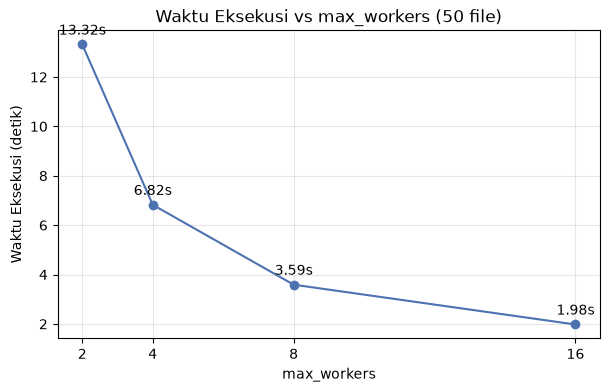

In [19]:
import time
import random
from concurrent.futures import ThreadPoolExecutor

random.seed(42)
daftar_file = [f"file_{i}.dat" for i in range(50)]
latensi_simulasi = {f: random.uniform(0.3, 0.8) for f in daftar_file}

def download_file(nama_file):
    durasi = latensi_simulasi[nama_file]
    time.sleep(durasi)
    ukuran_kb = round(durasi * 1000)
    return f"{nama_file} ({ukuran_kb} KB)"

worker_list = [2, 4, 8, 16]
waktu_pool = []

for w in worker_list:
    start = time.perf_counter()
    with ThreadPoolExecutor(max_workers=w) as executor:
        hasil = list(executor.map(download_file, daftar_file))
    waktu = time.perf_counter() - start
    waktu_pool.append(waktu)
    print(f"max_workers = {w:>2} -> {waktu:.2f} detik")

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(worker_list, waktu_pool, marker="o", color="#4c72b0")
for w, t in zip(worker_list, waktu_pool):
    plt.text(w, t + 0.4, f"{t:.2f}s", ha="center")
plt.xticks(worker_list)
plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.title("Waktu Eksekusi vs max_workers (50 file)")
plt.grid(alpha=0.3)
plt.show()

**Apakah menambah `max_workers` terus-menerus selalu mempercepat?** Jawabannya tidak. Waktu memang turun saat worker ditambah, tetapi penghematannya makin kecil (dari 2 ke 4 hemat sekitar 6 detik, dari 8 ke 16 hanya sekitar 1,6 detik). Ada titik jenuh karena:
1. Waktu total tidak bisa lebih kecil dari tugas terlama (sekitar 0,8 detik).
2. Thread yang terlalu banyak menambah overhead (memori dan context switching).
3. Pada download sungguhan, bandwidth jaringan atau batas koneksi server ikut membatasi, jadi tambahan thread tidak membuat lebih cepat.

## No.4

**Threading akan membantu:** web scraper atau pengunduh file. Programnya banyak menunggu respons jaringan (I/O-bound), dan saat satu thread menunggu, GIL dilepas sehingga thread lain bisa jalan. Waktu total jadi jauh lebih singkat.

**Threading tidak akan membantu:** pemrosesan ribuan gambar (resize atau filter). Ini pekerjaan CPU-bound, dan karena GIL hanya satu thread yang menjalankan bytecode pada satu waktu, sehingga banyak thread tidak mempercepat. Untuk kasus ini gunakan `multiprocessing` (Pertemuan 3) agar tiap proses punya GIL sendiri dan bisa memakai banyak core CPU.